### Problem 13 : Consent withdrawn - forgetting a face

⏱️ ~40 min · 🧭 Stage 6 (Real-world Responsible AI), rung 8 · 📄 `resources/papers/01-foundations/2015-cao-yang-towards-making-systems-forget.pdf`, book chapter on privacy (`resources/book/`)

> 🔗 **Building on Problem 12 :** there, each person was one row among 21,000, and their influence on the model was
> small. A face-recognition system is different : a person is not one row, **a person is a class**. The model was built
> to recognise *them*.

Dana works in an office that uses face recognition for door access. She leaves the company and **withdraws her
consent**. Under GDPR, facial templates are *biometric data*, a special category (Art. 9), consent can be withdrawn at
any time (Art. 7(3)), and erasure follows (Art. 17(1)(b)). Illinois' BIPA has similar rules with statutory damages. And
in **FTC v. Everalbum (2021)**, the company had to delete not only the photos but the **face-recognition models and
algorithms** built from them.

We use the **Olivetti faces** dataset (AT&T Laboratories Cambridge : 40 people, 10 photos each), downsampled to 32×32.

> 🟢 **In plain words :** a face-ID system has two parts : a "face reader" that turns a photo into numbers, and an
> address book of enrolled employees ("this pattern of numbers is Dana"). Deleting Dana means removing her from the
> address book **and** from the face reader, because the reader learned its idea of "what a face looks like" partly
> from her photos.

> 🔴 **For practitioners :** a recognition system = a learned **embedding** + a **gallery of templates** + a decision
> rule. Consent withdrawal touches all three. We do it exactly for a classical system (eigenfaces + nearest neighbour,
> rungs 1-2), approximately for a neural one (rungs 6-7), and then probe the part people forget : the embedding's
> *capability* to recognise her versus its *memory* of her.

**TASK :** Remove Dana from a classical and a neural face-ID system, prove it, and find out what unlearning *cannot*
do on its own.

280 training photos of 40 people; Dana = person 7, 7 training photos, 3 test photos


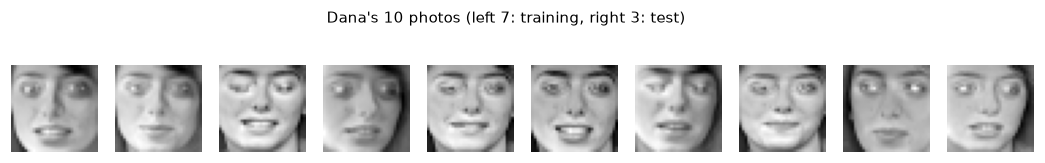

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mul import data, train, nn, methods, audit, viz
viz.style()

X, y = data.load_olivetti(side=32)
X = (X - X.mean(0)) / (X.std(0) + 1e-6)                       # standardise each pixel
tr = np.array([i for i in range(400) if i % 10 < 7])            # 7 photos per person to train / enrol
te = np.array([i for i in range(400) if i % 10 >= 7])           # 3 photos per person to test
X_train, y_train, X_test, y_test = X[tr], y[tr], X[te], y[te]

DANA = 7
forget = np.where(y_train == DANA)[0]; keep = np.where(y_train != DANA)[0]
dana_test = y_test == DANA
print(f"{len(X_train)} training photos of 40 people; Dana = person {DANA}, {len(forget)} training photos, {dana_test.sum()} test photos")

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for ax, i in zip(axes, range(DANA * 10, DANA * 10 + 10)):
    ax.imshow(X[i].reshape(32, 32), cmap="gray"); ax.axis("off")
plt.suptitle("Dana's 10 photos (left 7: training, right 3: test)", fontsize=10, y=1.05); plt.show()

#### Step 1 : Train - a classical face-ID system : eigenfaces + nearest neighbour

**Eigenfaces** (Turk & Pentland, 1991) : run PCA on the training photos. The top principal components, the
"eigenfaces", form a 40-dimensional face space. Each enrolled photo becomes a **template** (its coordinates in that
space), and a new photo is identified as the person with the nearest template.

The important detail for unlearning is *how* we compute PCA. The covariance matrix is built from two **sums** : `S1 =
Σ x` and `S2 = Σ x xᵀ`. That is the summation form from Problem 1, so a person can be subtracted exactly.

In [2]:
# Step 1: eigenfaces from sufficient statistics + a template gallery
class EigenfaceID:
    def __init__(self, k=40):
        self.k = k

    def fit(self, X, y):
        X64 = X.astype(np.float64)
        self.n, self.S1, self.S2 = len(X), X64.sum(0), X64.T @ X64        # the only things PCA needs
        self.gallery_X, self.gallery_y = X.copy(), y.copy()               # enrolled photos
        return self._refresh()

    def _refresh(self):
        mu = self.S1 / self.n
        w, V = np.linalg.eigh(self.S2 / self.n - np.outer(mu, mu))
        self.mu, self.V = mu, V[:, ::-1][:, :self.k]                      # top-k eigenfaces
        self.templates = self.embed(self.gallery_X)                      # re-embed the gallery in the new space
        return self

    def embed(self, X):
        return (X - self.mu) @ self.V

    def predict(self, X):
        d = ((self.embed(X)[:, None, :] - self.templates[None]) ** 2).sum(-1)
        return self.gallery_y[d.argmin(1)]

    def reconstruct(self, X):
        return self.mu + self.embed(X) @ self.V.T

    def unlearn(self, X_del, y_del, person):
        """Exact: subtract the person's photos from the PCA statistics AND delete their templates."""
        Xd = X_del.astype(np.float64)
        self.n, self.S1, self.S2 = self.n - len(Xd), self.S1 - Xd.sum(0), self.S2 - Xd.T @ Xd
        mask = self.gallery_y != person
        self.gallery_X, self.gallery_y = self.gallery_X[mask], self.gallery_y[mask]
        return self._refresh()

system = EigenfaceID(k=40).fit(X_train, y_train)
acc = lambda p, t: float(np.mean(p == t))
print(f"test accuracy (everyone): {acc(system.predict(X_test), y_test):.1%}   Dana's test photos: {acc(system.predict(X_test[dana_test]), y_test[dana_test]):.0%}")

test accuracy (everyone): 90.8%   Dana's test photos: 67%


#### Step 2 : Show the issue - Dana is inside the face space itself

Deleting Dana's templates from the gallery is the obvious step, and most systems stop there. But the **eigenfaces
were computed from her photos too**. A face space learned partly from Dana represents Dana's face especially well.
We can see that directly : project a photo into the 40-dimensional face space and reconstruct it. The lower the
reconstruction error, the better the face space "knows" that face.

Dana: error 0.264 in the face space built WITH her, 0.383 in one built WITHOUT her
all 40 people: error rises by 41% on average when the person is left out (min 14%, max 82%)


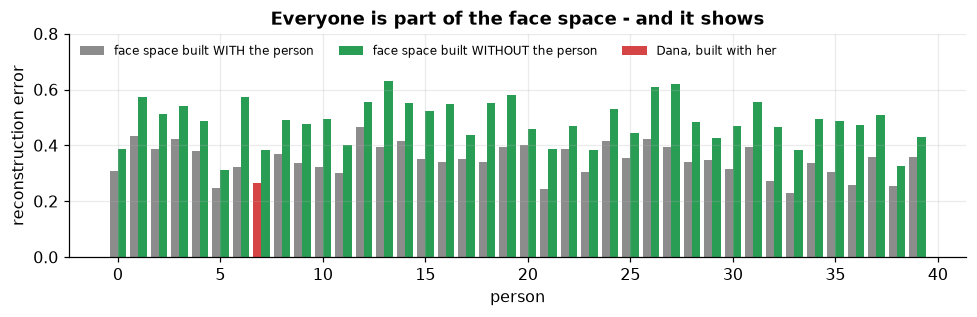

In [3]:
# Step 2: how well does the face space know Dana, compared with people it never saw?
def rec_error(sys_, Xq):
    Zc = Xq - sys_.mu
    return float(np.mean(np.linalg.norm(Zc - (Zc @ sys_.V) @ sys_.V.T, axis=1) / np.linalg.norm(Zc, axis=1)))

# For every person p: reconstruction error of p's photos in the face space built WITH p vs WITHOUT p
with_p = np.array([rec_error(system, X_train[y_train == p]) for p in range(40)])
without_p = np.array([rec_error(EigenfaceID(40).fit(X_train[y_train != p], y_train[y_train != p]), X_train[y_train == p]) for p in range(40)])
print(f"Dana: error {with_p[DANA]:.3f} in the face space built WITH her, {without_p[DANA]:.3f} in one built WITHOUT her")
print(f"all 40 people: error rises by {np.mean(without_p / with_p - 1):.0%} on average when the person is left out "
      f"(min {np.min(without_p / with_p - 1):.0%}, max {np.max(without_p / with_p - 1):.0%})")

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(np.arange(40) - 0.2, with_p, 0.4, color=viz.ORIGINAL, label="face space built WITH the person")
ax.bar(np.arange(40) + 0.2, without_p, 0.4, color=viz.RETRAIN, label="face space built WITHOUT the person")
ax.bar([DANA - 0.2], [with_p[DANA]], 0.4, color=viz.FORGET, label="Dana, built with her")
ax.set_xlabel("person"); ax.set_ylabel("reconstruction error"); ax.legend(fontsize=8, ncol=3, loc="upper left")
ax.set_ylim(0, 0.8); ax.set_title("Everyone is part of the face space - and it shows"); plt.tight_layout(); plt.show()

For **every** person, the face space reconstructs their photos noticeably better when it was built with them. Some
faces are simply more typical than others (that is why the bars vary), so the fair comparison is always the *same
person* with and without. For Dana, the error rises by almost half. Her face is literally part of the basis. Deleting
her templates alone would leave a system whose *face reader* still carries her.

#### Step 3 : Untrain - exact removal from the statistics and the gallery

In [4]:
# Step 3: exact unlearning, then check it against a system that never saw Dana
unlearned = EigenfaceID(k=40).fit(X_train, y_train).unlearn(X_train[forget], y_train[forget], DANA)
scratch = EigenfaceID(k=40).fit(X_train[keep], y_train[keep])

same_space = np.abs(np.abs(unlearned.V.T @ scratch.V).diagonal()).min()     # eigenvectors match up to sign
print(f"eigenfaces: min |cos| between unlearned and from-scratch = {same_space:.12f}")
print(f"identical predictions on every test photo: {np.array_equal(unlearned.predict(X_test), scratch.predict(X_test))}")

eigenfaces: min |cos| between unlearned and from-scratch = 1.000000000000
identical predictions on every test photo: True


#### Step 4 : Show the result

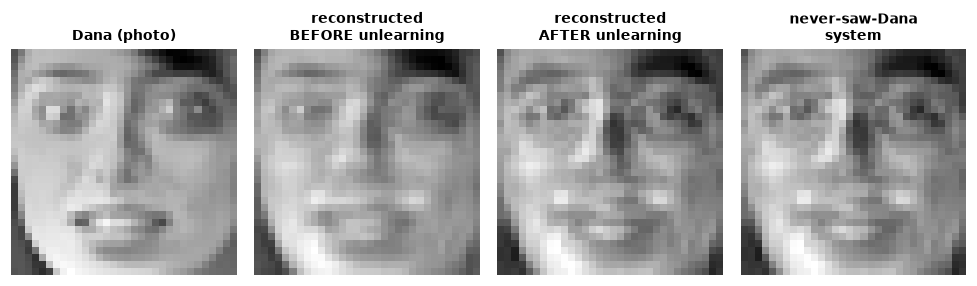

reconstruction error of Dana's photos: before 0.264 → after 0.383   (never-saw-Dana system: 0.383)
Dana's test photos are now identified as persons [0, 0, 0] - she is no longer in the system


In [5]:
# Step 4: Dana's face through the face space, before and after
i = forget[0]
fig, axes = plt.subplots(1, 4, figsize=(9, 2.6))
for ax, (title, img) in zip(axes, [("Dana (photo)", X_train[i]),
                                   ("reconstructed\nBEFORE unlearning", system.reconstruct(X_train[[i]])[0]),
                                   ("reconstructed\nAFTER unlearning", unlearned.reconstruct(X_train[[i]])[0]),
                                   ("never-saw-Dana\nsystem", scratch.reconstruct(X_train[[i]])[0])]):
    ax.imshow(img.reshape(32, 32), cmap="gray"); ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()
print(f"reconstruction error of Dana's photos: before {rec_error(system, X_train[forget]):.3f} → after {rec_error(unlearned, X_train[forget]):.3f}"
      f"   (never-saw-Dana system: {rec_error(scratch, X_train[forget]):.3f})")
pred = unlearned.predict(X_test[dana_test])
print(f"Dana's test photos are now identified as persons {pred.tolist()} - she is no longer in the system")

After unlearning, Dana's face is reconstructed exactly as the never-saw-Dana system reconstructs it (the two *are* the
same system), and her photos now match other employees. A real door would also apply a similarity threshold, so she
would simply not be recognised. This is **exact** unlearning, at the cost of one 1024×1024 eigen-decomposition and
re-embedding the gallery.

#### The neural system : identity forgetting

Modern face-ID uses a neural network. We train an MLP (1024 → 256 → 128 → 40) to classify the 40 people, then remove
Dana with each method from Problems 6-10, audited with the Problem 11 protocol. Deleting one identity is a **class**
request, the kind on which anchored methods did well in Problems 9 and 11.

In [6]:
# Neural face-ID: train, references, every method, the Problem 11 audit
FIT = dict(epochs=60, lr=1e-3, batch_size=32)
mlp = lambda: nn.MLP(1024, 40, (256, 128))
Xr, yr, Xf, yf = X_train[keep], y_train[keep], X_train[forget], y_train[forget]
splits = dict(Xr=Xr, yr=yr, Xf=Xf, yf=yf, Xt=X_test[~dana_test], yt=y_test[~dana_test])

net = train.fit(mlp, X_train, y_train, seed=0, **FIT)
OUT = [train.fit(mlp, Xr, yr, seed=s, **FIT) for s in range(100, 112)]
IN = [train.fit(mlp, X_train, y_train, seed=s, **FIT) for s in range(1, 9)]
band_mean, band_std = audit.gold_band(OUT, splits, in_models=IN, mia=False)

runs = {"original": net,
        "retrain": train.fit(mlp, Xr, yr, seed=999, **FIT),
        "fine-tune": methods.finetune(net, Xr, yr, epochs=5, lr=1e-3)[0],
        "gradient ascent": methods.gradient_ascent(net, Xf, yf, epochs=5, lr=1e-4)[0],
        "NegGrad+": methods.neggrad_plus(net, Xr, yr, Xf, yf, epochs=5, alpha=0.9, lr=1e-4)[0],
        "SCRUB": methods.scrub(net, Xr, yr, Xf, steps=8, max_steps=4, lr=5e-4, forget_batch_size=8, T=1.0)[0],
        "Bad Teacher": methods.bad_teacher(net, mlp, Xr, Xf)[0]}
table = audit.audit(runs, splits, OUT, in_models=IN, mia=False)
table = table.join(audit.gate(table, band_mean, band_std))
table["dana_test_acc"] = [train.accuracy(m, X_test[dana_test], y_test[dana_test]) for m in runs.values()]
print(f"test accuracy of the original on everyone: {train.accuracy(net, X_test, y_test):.1%}")
print(table[["forget_acc", "dana_test_acc", "test_acc", "ulira", "FORGET", "PRIVACY", "UTILITY", "verdict"]].round(3).to_string())

test accuracy of the original on everyone: 91.7%
                 forget_acc  dana_test_acc  test_acc  ulira FORGET PRIVACY UTILITY verdict
method                                                                                    
original              1.000          0.667     0.923  1.000      x       x      ok    FAIL
retrain               0.000          0.000     0.932  0.000     ok      ok      ok    PASS
fine-tune             0.143          0.000     0.821  0.429      x       x       x    FAIL
gradient ascent       1.000          0.667     0.932  0.857      x       x      ok    FAIL
NegGrad+              0.000          0.000     0.923  0.000     ok      ok      ok    PASS
SCRUB                 0.000          0.000     0.932  0.000     ok      ok      ok    PASS
Bad Teacher           0.000          0.000     0.923  0.000     ok      ok      ok    PASS


As in Problem 11's class request, several methods pass : the target is unambiguous (a network that never saw Dana has
no output for her, so her photos go to other people), and the anchored methods hit it without hurting anyone else.
Plain fine-tuning and gradient ascent at their defaults do not get there.

By the standards of Problem 11, the job looks done. **Now the part that is easy to miss.**

#### Step 5 : Prove it - memory versus capability

The 40-way output layer is only the "address book". The real asset of a face model is its **embedding**, the hidden
layer (`model.features`), which deployed systems use to compare a new photo with enrolled templates. So let's attack
the embedding the way a deployed system would use it : **enrol** Dana again from her 3 test photos (one template per
person, everyone else enrolled the same way), then try to identify her **7 deleted training photos** by nearest
template.

retrained references (never saw Dana): [0.86, 0.71, 0.71, 1.0, 0.86, 0.86, 1.0, 0.43, 1.0, 1.0, 0.71, 0.86]  →  mean 83%
original           1.000
retrain            1.000
fine-tune          1.000
gradient ascent    1.000
NegGrad+           0.714
SCRUB              0.857
Bad Teacher        0.857


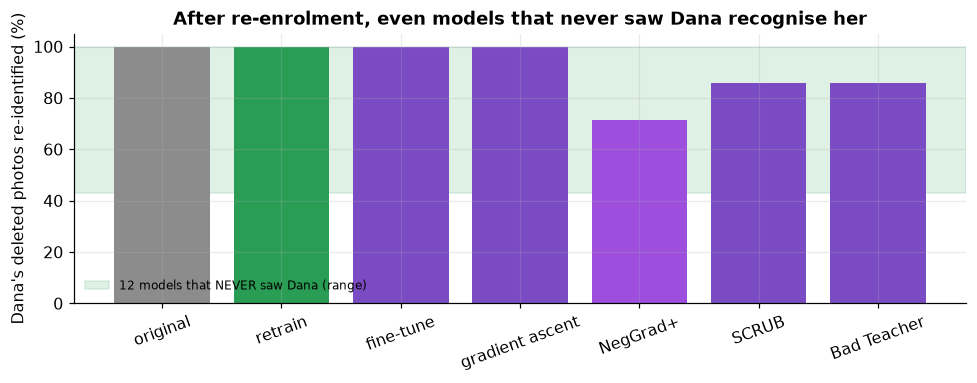

In [7]:
# Step 5: can the embedding still recognise Dana's DELETED photos if someone enrols her again?
def reidentify(model, person=DANA):
    E_gal, E_q = model.features(X_test), model.features(X_train[y_train == person])
    T = np.stack([E_gal[y_test == c].mean(0) for c in range(40)])                     # one template per person
    T = T / (np.linalg.norm(T, axis=1, keepdims=True) + 1e-9)
    Q = E_q / (np.linalg.norm(E_q, axis=1, keepdims=True) + 1e-9)
    return float(np.mean((Q @ T.T).argmax(1) == person))                             # cosine nearest template

ref = np.array([reidentify(m) for m in OUT])
reid = pd.Series({k: reidentify(m) for k, m in runs.items()}, name="re-identified")
print(f"retrained references (never saw Dana): {ref.round(2).tolist()}  →  mean {ref.mean():.0%}")
print(reid.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axhspan(100 * ref.min(), 100 * ref.max(), color=viz.RETRAIN, alpha=0.15, label="12 models that NEVER saw Dana (range)")
ax.bar(range(len(reid)), 100 * reid.values, color=[viz.color_for(n) for n in reid.index])
ax.set_xticks(range(len(reid))); ax.set_xticklabels(reid.index, rotation=20); ax.set_ylim(0, 105)
ax.set_ylabel("Dana's deleted photos re-identified (%)"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("After re-enrolment, even models that never saw Dana recognise her")
plt.tight_layout(); plt.show()

**Stop and notice what just happened.** Models that **never saw a single photo of Dana** match her deleted photos to
her new template most of the time. So do all the unlearned models. There is nothing left to unlearn here : recognising
faces it has never seen is the *job* of a face embedding. That is why it works at a new office on day one.

This separates two things that are easy to confuse :

| | Memory (what unlearning removes) | Capability (what unlearning cannot remove) |
|---|---|---|
| What it is | the influence of Dana's photos on the weights | the ability to match *any* face to an enrolled template |
| Measured by | gold band, U-LiRA, relearn, the reconstruction test | re-identification after enrolment |
| Removed by retraining? | ✅ | ❌ - retrained models have it too |
| What actually protects Dana | unlearning | **deleting her templates and refusing re-enrolment** |

> 🔴 **For practitioners :** consent withdrawal in a biometric system is a **three-part** operation : (1) delete the
> templates and raw images, (2) unlearn her from the embedding model (or document that the model was trained without
> her, or retrain on schedule), (3) stop re-enrolment, which is the hard part. A "do-not-enrol" list made of her face
> embedding would *itself* be biometric processing of someone who withdrew consent. The usual pattern is a
> **non-biometric** suppression key (employee ID, account ID) checked at enrolment time. The EDPB's view (Opinion
> 28/2024) that a model is personal data if personal data can be *extracted* from it applies to part (2). Part (3)
> is a product and process decision, and no model change can do it for you.

One more honest check : the relearn attack from Problem 11.

In [8]:
# The relearn test on an identity
rl, ref_steps = audit.relearn_test(runs, Xf, yf, OUT, net)
print(f"retrained references relearn Dana in {sorted(ref_steps)} steps")
print(rl.T.to_string())

retrained references relearn Dana in [2, 3, 3, 4, 4, 4, 5, 5, 5, 5, 6, 6] steps
              original retrain fine-tune gradient ascent NegGrad+ SCRUB Bad Teacher
relearn_steps        0       6         1               0        3    15           3
RELEARN              x      ok         x               x       ok    ok          ok


Like the digit-3 class in Problem 11, everyone relearns Dana in a handful of steps, including models that never saw
her : learning one more face from 3 photos is what a good face model *should* be able to do. The relearn test cannot
separate memory from capability for an identity. The reconstruction test (classical) and U-LiRA (neural) can.

----
#### OUTCOME :

| | Eigenfaces + nearest neighbour | Neural face-ID |
|---|---|---|
| Where Dana lives | the PCA statistics **and** the gallery | the weights **and** the gallery |
| Unlearning | exact : subtract sums, delete templates, re-embed | anchored methods pass the class-style audit; fine-tune / GA do not |
| Proof | identical eigenfaces and predictions to a from-scratch system | gold band + U-LiRA |
| Can she be recognised after re-enrolment? | yes | yes - **even by models that never saw her** |
| What protects her from that | template deletion + a non-biometric do-not-enrol key | same |

#### Key Takeaways :

- In face recognition a person is a **class** : her data shapes the embedding, not just one output.
- Deleting templates is **not** enough. The feature extractor (eigenfaces or a network) was learned from her photos
  too. Eigenfaces can be unlearned **exactly** because PCA only needs sums.
- Neural identity forgetting is a class request : anchored methods pass the audit.
- **Memory ≠ capability.** Unlearning removes the influence of her data. It cannot remove the model's ability to
  recognise a face someone enrols again. That protection comes from **process** : template deletion and a
  non-biometric do-not-enrol list.

#### TASK :
1. Change `DANA` to three other people. Is the reconstruction-error gap similar for everyone? Who is "easiest" to
   forget, and why might that be (look at their photos)?
2. Reduce `k` from 40 to 10 eigenfaces. Does the gap between "built with her" and "never saw her" shrink? Connect your
   answer to memorisation : a smaller model has less room to store individuals.
3. Raise the MLP's hidden sizes to (512, 256). Does re-identification of Dana by never-saw-her models go up or down?
   What does that say about larger face models?
4. Write the three-step consent-withdrawal procedure for this system as a checklist a DPO could sign, including the
   evidence for each step. (Problem 17 collects it.)

#### ❓ Open question → Problem 14
Dana's photos were legitimate data that she asked to remove. **What if the data that must go is *malicious*,
poisoned examples planted to make the model misbehave, and we only find *some* of them?** That is Problem 14.